# Session 6 — Artificial Neural Networks

**Adapted for this repository.** This is the Session 6 class notebook with three changes: (1) the course helper package
`common` is replaced by this repo's own code (`src/milk10k`: lesion-level splits from `artifacts/splits`, the 33 features
cached by `features.py`); (2) every "Session 5" reference number is read from *our* `artifacts/session05` results, because our
splits differ from the instructor's, so the numbers quoted in the slides (forest 0.534, MLP 0.493) do not apply; (3) the
mini-challenge (§11) is answered below it. The homework is in `06_homework.ipynb`.

#### 0. Setup

In [1]:

# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import copy
import torch
import torch.nn as nn


### 1. One neuron, by hand → in NumPy

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b):
    z = np.dot(x, w) + b          # 1. weighted sum
    return z, sigmoid(z)          # 2. activation

x = np.array([0.6, 0.2])          # edge density, color asymmetry (normalized)
w = np.array([1.5, -0.5])
b = -0.4
neuron(x, w, b)                   # (0.4, 0.599)

(np.float64(0.3999999999999999), np.float64(0.598687660112452))

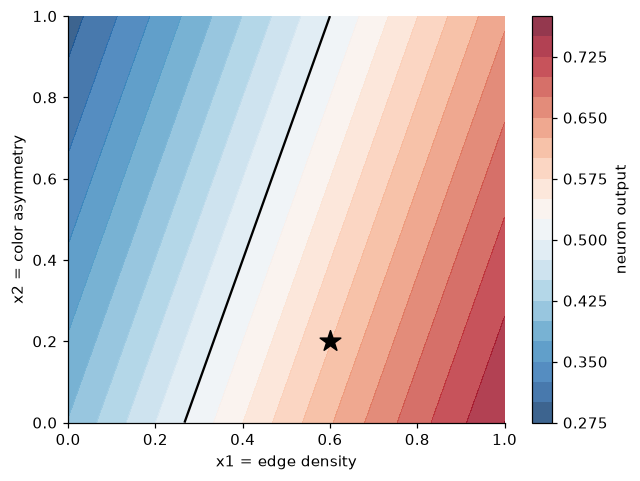

In [3]:
g1, g2 = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
_, p = neuron(np.stack([g1, g2], axis=-1), w, b)       # works on the whole grid at once

plt.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.8)
plt.colorbar(label="neuron output")
plt.contour(g1, g2, p, levels=[0.5], colors="k")       # the decision boundary: z = 0
plt.scatter(*x, c="k", marker="*", s=200)              # our lesion: 0.599
plt.xlabel("x1 = edge density"); plt.ylabel("x2 = color asymmetry");

### 2. XOR — what one line cannot do

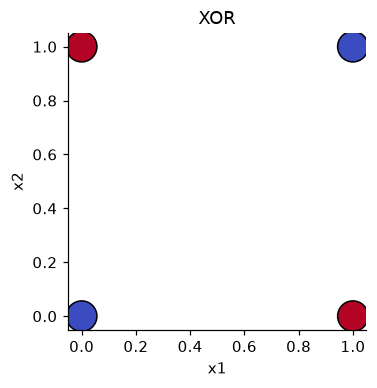

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

plt.figure(figsize=(3.5, 3.5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("XOR");

In [5]:
def relu(z):
    return np.maximum(0, z)

W1 = np.array([[1, 1],
               [1, 1]], dtype=float)     # column j = weights of hidden neuron j
b1 = np.array([0, -1], dtype=float)
W2 = np.array([1, -2], dtype=float)

H = relu(X_xor @ W1 + b1)                # hidden layer: 4 inputs x 2 neurons
out = H @ W2
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1],
              "h1": H[:, 0], "h2": H[:, 1], "output": out, "XOR": y_xor})

,x1,x2,h1,h2,output,XOR
0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,1.0,1.0,0.0,1.0,1
2,1.0,0.0,1.0,0.0,1.0,1
3,1.0,1.0,2.0,1.0,0.0,0


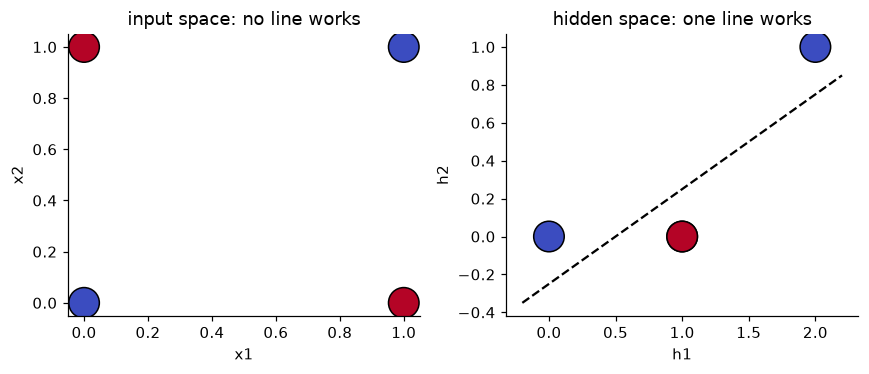

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
axes[0].set_title("input space: no line works"); axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
h1_line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(h1_line, (h1_line - 0.5) / 2, "k--")       # output = h1 - 2*h2 = 0.5
axes[1].set_title("hidden space: one line works"); axes[1].set_xlabel("h1"); axes[1].set_ylabel("h2")
plt.tight_layout()

In [7]:
linear_out = (X_xor @ W1 + b1) @ W2               # same network, NO ReLU
collapsed = X_xor @ (W1 @ W2) + (b1 @ W2)          # one equivalent linear layer
print(linear_out, collapsed)                       # [2. 1. 1. 0.] twice -> not XOR
print(W1 @ W2, b1 @ W2)                            # [-1. -1.] 2.0

[2. 1. 1. 0.] [2. 1. 1. 0.]
[-1. -1.] 2.0


### 3. Forward pass, softmax, cross-entropy

In [8]:
def forward(x, W1, b1, W2, b2):
    z_h = x @ W1 + b1          # hidden pre-activations
    h = relu(z_h)              # hidden activations
    z_o = h @ W2 + b2          # output pre-activation
    return sigmoid(z_o), h, z_h

W1 = np.array([[0.5, -0.3],
               [0.3,  0.4]]); b1 = np.array([0.1, -0.3])
W2 = np.array([0.4, -0.2]);   b2 = 0.1

y_hat, h, z_h = forward(np.array([0.6, 0.2]), W1, b1, W2, b2)
print(z_h, h, y_hat)           # [ 0.46 -0.4 ] [0.46 0.  ] 0.570

[ 0.46 -0.4 ] [0.46 0.  ] 0.5705266031962988


In [9]:
def softmax(z):
    e = np.exp(z - z.max())    # subtract max: same result, no overflow
    return e / e.sum()

logits = np.array([1.0, 2.0, 0.5])          # Benign, Malignant, Indeterminate
print(np.exp(logits))                       # [2.718 7.389 1.649]
print(softmax(logits))                      # [0.231 0.629 0.14 ]

[2.718 7.389 1.649]
[0.231 0.629 0.14 ]


In [10]:
def cross_entropy(y_true_onehot, probs, eps=1e-9):
    probs = np.clip(probs, eps, 1 - eps)                 # avoid log(0)
    return -np.sum(y_true_onehot * np.log(probs))

y_true = np.array([0, 1, 0])                             # truth: Malignant
for probs in ([0.10, 0.70, 0.20], [0.005, 0.99, 0.005], [0.80, 0.10, 0.10]):
    print(probs, "->", round(cross_entropy(y_true, np.array(probs)), 3))   # 0.357 / 0.01 / 2.303

[0.1, 0.7, 0.2] -> 0.357
[0.005, 0.99, 0.005] -> 0.01
[0.8, 0.1, 0.1] -> 2.303


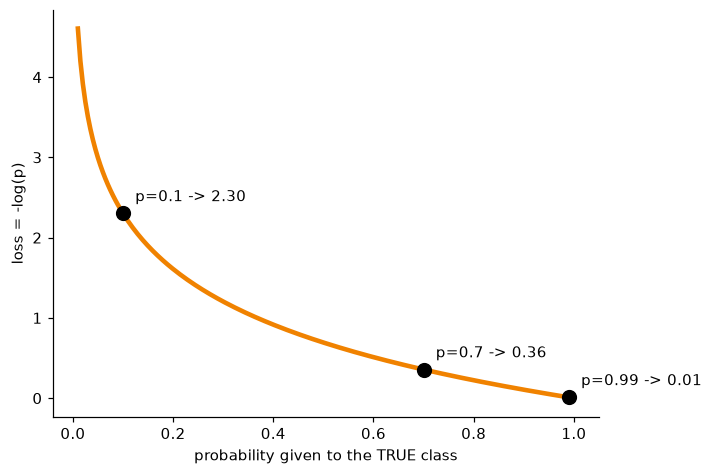

In [11]:
p = np.linspace(0.01, 1, 200)
plt.plot(p, -np.log(p), color="#F08200", lw=3)
for q in (0.10, 0.70, 0.99):
    plt.scatter(q, -np.log(q), s=80, color="k", zorder=3)
    plt.annotate(f"p={q} -> {-np.log(q):.2f}", (q, -np.log(q)), xytext=(8, 8), textcoords="offset points")
plt.xlabel("probability given to the TRUE class"); plt.ylabel("loss = -log(p)");

### 4. Gradient descent by hand

In [12]:
def descend(lr, w=0.0, steps=15):
    path = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)       # slope of (w - 3)**2
        w = w - lr * grad        # one step downhill
        path.append(w)
    return np.array(path)

path = descend(lr=0.1)
print(path[:4])                  # [0.    0.6   1.08  1.464]
print(path[-1])                  # 2.894 after 15 steps -> close to 3

[0.    0.6   1.08  1.464]
2.894446883733504


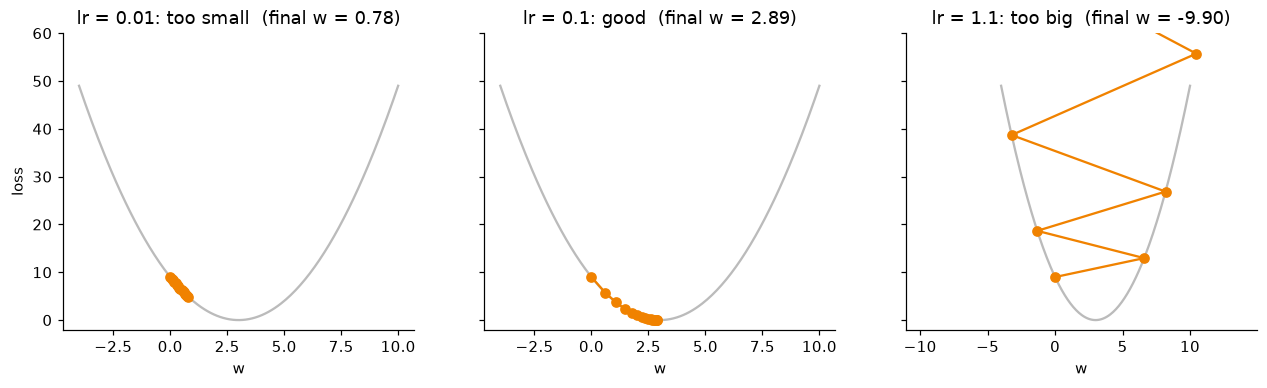

In [13]:
ws = np.linspace(-4, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, lr, title in zip(axes, [0.01, 0.1, 1.1], ["too small", "good", "too big"]):
    path = descend(lr, steps=8 if lr > 1 else 15)
    ax.plot(ws, (ws - 3) ** 2, color="#BBBBBB")
    ax.plot(path, (path - 3) ** 2, "o-", color="#F08200")
    ax.set_title(f"lr = {lr}: {title}  (final w = {path[-1]:.2f})")
    ax.set_ylim(-2, 60); ax.set_xlabel("w")
axes[0].set_ylabel("loss");

### 5. Backpropagation by hand — then let PyTorch check us

In [14]:
y = 1.0                                       # truth: malignant
z, y_hat = neuron(x, w, b)
loss = -np.log(y_hat)
print(f"forward : z={z:.3f}  y_hat={y_hat:.3f}  loss={loss:.3f}")      # 0.4  0.599  0.513

dz = y_hat - y                                # dLoss/dz for sigmoid + cross-entropy
grad_w = dz * x                               # chain rule: dLoss/dw = dLoss/dz * dz/dw = dz * x
grad_b = dz * 1
print(f"backward: dz={dz:.3f}  grad_w={grad_w}  grad_b={grad_b:.3f}")  # -0.401  [-0.241 -0.08 ]  -0.401

forward : z=0.400  y_hat=0.599  loss=0.513
backward: dz=-0.401  grad_w=[-0.241 -0.08 ]  grad_b=-0.401


In [15]:
lr = 1.0
w_new = w - lr * grad_w
b_new = b - lr * grad_b
z2, y_hat2 = neuron(x, w_new, b_new)
print(w_new, round(b_new, 3))                                  # [ 1.741 -0.42 ]  0.001
print(f"y_hat {y_hat:.3f} -> {y_hat2:.3f}   loss {loss:.3f} -> {-np.log(y_hat2):.3f}")   # 0.599 -> 0.723   0.513 -> 0.324

[ 1.741 -0.42 ] 0.001
y_hat 0.599 -> 0.723   loss 0.513 -> 0.324


In [16]:
import torch
import torch.nn as nn

xt = torch.tensor([0.6, 0.2])
wt = torch.tensor([1.5, -0.5], requires_grad=True)   # track gradients for these
bt = torch.tensor(-0.4, requires_grad=True)

y_hat_t = torch.sigmoid(xt @ wt + bt)                # forward, same formula
loss_t = -torch.log(y_hat_t)
loss_t.backward()                                    # backpropagation, automatic

print(y_hat_t.item(), loss_t.item())                 # 0.599  0.513
print(wt.grad, bt.grad)                              # tensor([-0.2408, -0.0803])  tensor(-0.4013)

0.5986876487731934 0.5130152702331543
tensor([-0.2408, -0.0803]) tensor(-0.4013)


### 6. A real (tiny) network learns a curved boundary

In [17]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xm_t = torch.tensor(Xm, dtype=torch.float32)
ym_t = torch.tensor(ym)

def make_net(hidden):
    torch.manual_seed(0)
    if hidden == 0:
        return nn.Linear(2, 2)                            # no hidden layer = logistic regression
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, 2))

net = make_net(8)
net

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)

In [18]:
def train(net, X, y, epochs=1000, lr=0.01):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        optimizer.zero_grad()            # 1. forget old gradients
        loss = loss_fn(net(X), y)        # 2. forward + loss
        loss.backward()                  # 3. backprop
        optimizer.step()                 # 4. w <- w - lr * grad  (Adam's version)
    return loss.item()

def plot_boundary(net, ax, title):
    g1, g2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        p = torch.softmax(net(grid), dim=1)[:, 1].reshape(g1.shape)
    ax.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

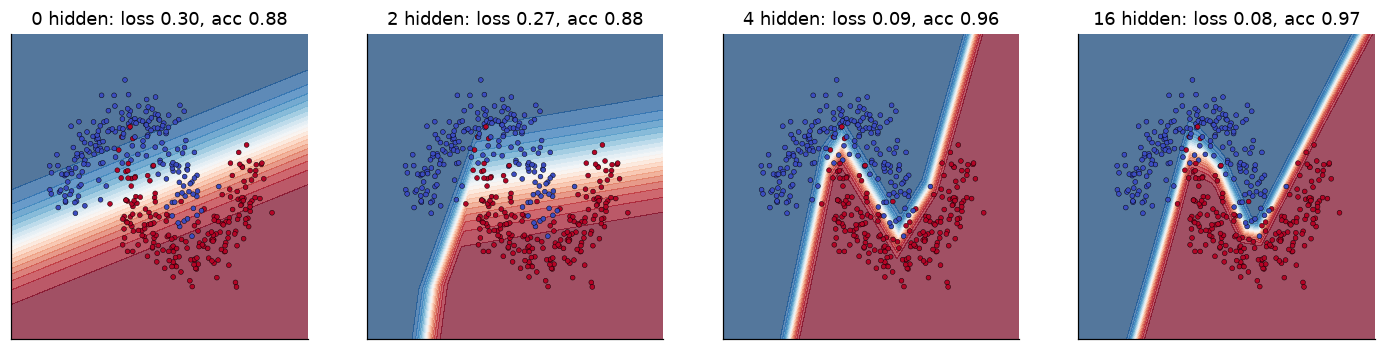

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, hidden in zip(axes, [0, 2, 4, 16]):
    net = make_net(hidden)
    final_loss = train(net, Xm_t, ym_t)
    with torch.no_grad():
        acc = (net(Xm_t).argmax(1) == ym_t).float().mean().item()
    plot_boundary(net, ax, f"{hidden} hidden: loss {final_loss:.2f}, acc {acc:.2f}")
# acc: 0 hidden 0.88 (a line) · 2 hidden 0.88 · 4 hidden 0.96 · 16 hidden 0.97

### 7. Back to MILK10k — Session 5's 33 features

In [20]:

from PIL import Image
from scipy import ndimage

# ---- Session 5 ---------------------------------------------------------------
def color_stats(rgb):
    return np.concatenate([rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])

def color_histogram(rgb, bins=8):
    n_pixels = rgb.shape[0] * rgb.shape[1]
    return np.concatenate([np.histogram(rgb[:, :, c], bins=bins, range=(0, 256))[0] / n_pixels
                           for c in range(3)])

def texture_features(rgb):
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    return np.array([np.hypot(gx, gy).mean(),
                     (local_sq_mean - local_mean**2).mean(),
                     ndimage.laplace(gray).var()])

def extract_features(isic_id):
    rgb = np.array(Image.open(mk.config.IMAGE_DIR / f"{isic_id}.jpg").convert("RGB").resize((200, 150)), dtype=float)
    return np.concatenate([color_stats(rgb), color_histogram(rgb), texture_features(rgb)])
# ------------------------------------------------------------------------------------------

# This repo's committed, lesion-level splits (Session 3: leak-free), dermoscopic image per lesion.
frames = F.load_lesion_splits()
train_df, val_df, test_df = [frames[k].assign(isic_id=frames[k]["derm_id"]) for k in ("train", "val", "test")]

# The same 33 features, from the cache written by src/milk10k/features.py (extracted once for all images).
cols = F.FEATURE_GROUPS["color_stats"] + F.FEATURE_GROUPS["color_hist"] + F.FEATURE_GROUPS["texture"]
feats = F.feature_table(pd.concat([d["isic_id"] for d in (train_df, val_df, test_df)]),
                        cache=F.FEATURE_DIR / "features.npz")
data = {f"X_{n}": feats.loc[d["isic_id"], cols].to_numpy()
        for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
assert np.allclose(data["X_val"][:5], np.stack([extract_features(i) for i in val_df["isic_id"][:5]]))   # cache == the code above

X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
print(X_train.shape, X_val.shape, X_test.shape)

# Session 5 results on THESE splits (artifacts/session05, written by notebooks/05_classical_baseline.ipynb)
baseline = json.loads((ROOT / "artifacts" / "session05" / "baseline_scores.json").read_text())
grid = pd.read_csv(ROOT / "artifacts" / "session05" / "feature_model_grid.csv")
g33 = grid[grid["feature set"] == "Session 5 set (33)"].set_index("model")["val_f1"]
FOREST = baseline["forest_33"]["val_macro_f1"]
print(f"Session 5 on the same 33 features, val macro-F1: majority {g33['majority']:.3f}, "
      f"logreg {g33['logistic regression']:.3f}, kNN {g33['kNN (k=15)']:.3f}, forest {FOREST:.3f}")


(3742, 33) (749, 33) (749, 33)
Session 5 on the same 33 features, val macro-F1: majority 0.273, logreg 0.438, kNN 0.438, forest 0.575


In [21]:
from sklearn.preprocessing import StandardScaler

CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}
y_train = torch.tensor(train_df["diagnosis_1"].map(to_int).to_numpy())
y_val = torch.tensor(val_df["diagnosis_1"].map(to_int).to_numpy())
y_test = torch.tensor(test_df["diagnosis_1"].map(to_int).to_numpy())

scaler = StandardScaler().fit(X_train)                       # train only
Xtr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
Xva = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
Xte = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

print(Xtr.dtype, Xtr.shape, y_train[:10])
print(torch.bincount(y_train))

torch.float32 torch.Size([3742, 33]) tensor([2, 2, 2, 2, 2, 2, 0, 2, 2, 0])
tensor([1058,   89, 2595])


In [22]:
class_weights = len(y_train) / (3 * torch.bincount(y_train).float())
class_weights

tensor([ 1.1790, 14.0150,  0.4807])

### 8. An MLP on MILK10k — mini-batches, epochs, curves

In [23]:
def make_mlp(hidden=(64,), dropout=0.0, seed=0):
    torch.manual_seed(seed)                     # same initial weights for everyone
    layers, d_in = [], 33
    for h in hidden:
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, 3))           # 3 logits, no softmax (it's inside the loss)
    return nn.Sequential(*layers)

model = make_mlp()
print(model)
print(sum(p.numel() for p in model.parameters()))        # 2371

Sequential(
  (0): Linear(in_features=33, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=3, bias=True)
)
2371


In [24]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=64, shuffle=True)
print(len(train_loader))
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                                 # torch.Size([64, 33]) torch.Size([64])

59
torch.Size([64, 33]) torch.Size([64])


In [25]:
from sklearn.metrics import f1_score, accuracy_score

def fit(model, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64):
    loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_logits = model(Xva)
            history.append({"epoch": epoch,
                            "train_loss": total / len(Xtr),
                            "val_loss": loss_fn(val_logits, y_val).item(),
                            "val_f1": f1_score(y_val, val_logits.argmax(1), average="macro")})
    return pd.DataFrame(history).set_index("epoch")

t0 = time.perf_counter()
model = make_mlp()
hist = fit(model)
print(f"{time.perf_counter() - t0:.0f} s")
hist.iloc[[0, 9, 19, 29, 39, 49]].round(3)

2 s


,train_loss,val_loss,val_f1
epoch,,,
0,1.028,1.001,0.426
9,0.799,0.896,0.445
19,0.748,0.893,0.470
29,0.701,0.884,0.477
39,0.672,0.963,0.485
49,0.642,1.038,0.489


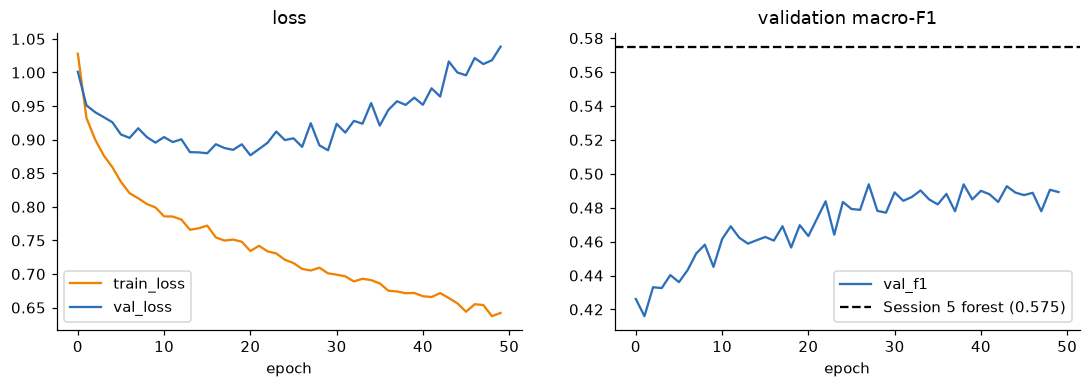

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=axes[0], color=["#F08200", "#2E6FBA"], title="loss")
hist["val_f1"].plot(ax=axes[1], color="#2E6FBA", title="validation macro-F1")
axes[1].axhline(FOREST, color="k", ls="--", label=f"Session 5 forest ({FOREST:.3f})")
axes[1].legend();

In [27]:
model.eval()
with torch.no_grad():
    val_pred = model(Xva).argmax(1)
mlp_val_f1 = f1_score(y_val, val_pred, average="macro")
print(f"MLP val macro-F1 = {mlp_val_f1:.3f}   (Session 5: majority {g33['majority']:.3f}, logreg {g33['logistic regression']:.3f}, kNN {g33['kNN (k=15)']:.3f}, forest {FOREST:.3f})")

MLP val macro-F1 = 0.489   (Session 5: majority 0.273, logreg 0.438, kNN 0.438, forest 0.575)


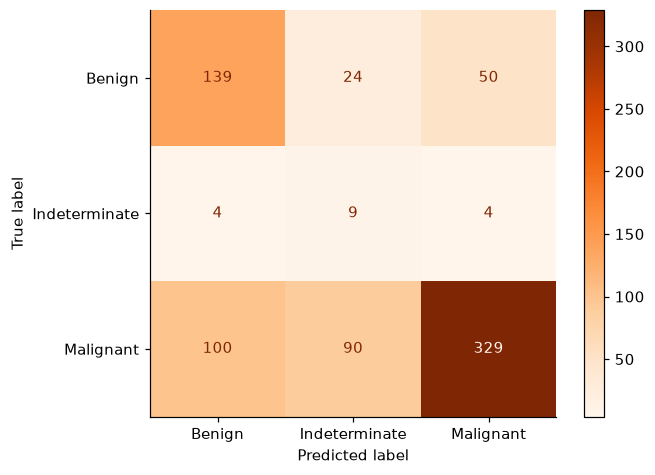

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=CLASSES, cmap="Oranges");

### 9. Overfitting on purpose — and three cures

75267


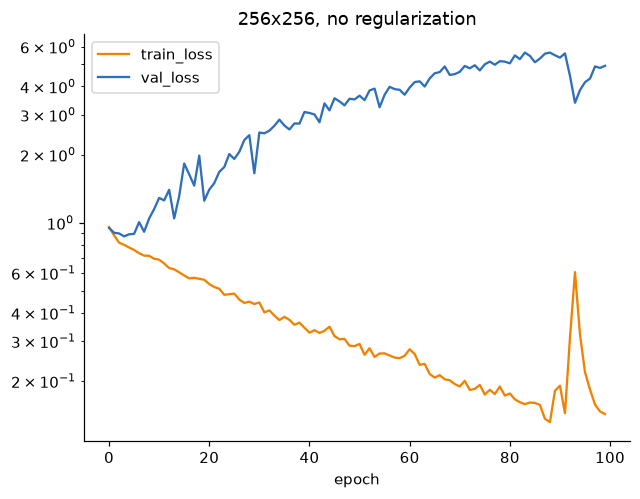

In [29]:
big = make_mlp(hidden=(256, 256))
print(sum(p.numel() for p in big.parameters()))           # 75267 weights
hist_big = fit(big, epochs=100)
hist_big[["train_loss", "val_loss"]].plot(color=["#F08200", "#2E6FBA"], logy=True,
                                          title="256x256, no regularization");

{'train_loss': 0.143, 'val_loss': 4.933, 'val_f1': 0.523}
{'train_loss': 0.402, 'val_loss': 2.487, 'val_f1': 0.492}


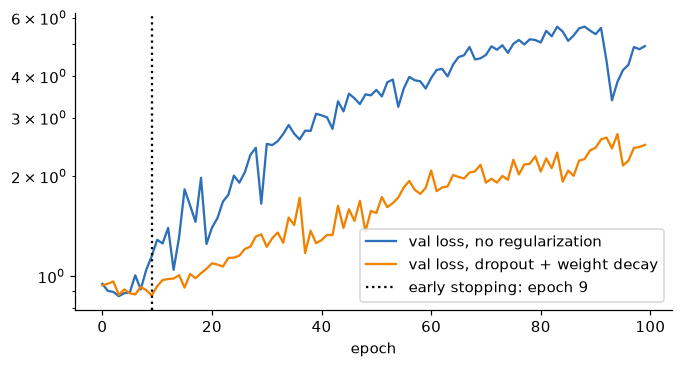

In [30]:
reg = make_mlp(hidden=(256, 256), dropout=0.3)
hist_reg = fit(reg, epochs=100, weight_decay=1e-4)

fig, ax = plt.subplots(figsize=(7, 3.5))
hist_big["val_loss"].plot(ax=ax, label="val loss, no regularization", color="#2E6FBA", logy=True)
hist_reg["val_loss"].plot(ax=ax, label="val loss, dropout + weight decay", color="#F08200")
best_epoch = hist_reg["val_loss"].idxmin()
ax.axvline(best_epoch, color="k", ls=":", label=f"early stopping: epoch {best_epoch}")
ax.legend();
print(hist_big.iloc[-1].round(3).to_dict())
print(hist_reg.iloc[-1].round(3).to_dict())

### 10. The test set — once — and the scoreboard

In [31]:
with torch.no_grad():
    test_pred = model(Xte).argmax(1)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
print(f"TEST accuracy = {test_acc:.3f}   TEST macro-F1 = {test_f1:.3f}")

scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": [baseline["forest_33"]["val_macro_f1"], baseline["forest_33"]["test_macro_f1"]],
    "Session 6 - MLP 33-64-3 (33 features)": [round(mlp_val_f1, 3), round(test_f1, 3)],
}, index=["val macro-F1", "test macro-F1"]).T
scoreboard

TEST accuracy = 0.633   TEST macro-F1 = 0.480


,val macro-F1,test macro-F1
Session 5 - random forest (33 features),0.575,0.528
Session 6 - MLP 33-64-3 (33 features),0.489,0.480


In [32]:
out_dir = ROOT / "artifacts" / "session06"
out_dir.mkdir(parents=True, exist_ok=True)
scores = {"model": "MLP 33-64-3 on Session 5's 33 handcrafted features",
          "val_macro_f1": round(float(mlp_val_f1), 3),
          "test_accuracy": round(float(test_acc), 3),
          "test_macro_f1": round(float(test_f1), 3)}
(out_dir / "mlp_scores.json").write_text(json.dumps(scores, indent=2))
scores

{'model': "MLP 33-64-3 on Session 5's 33 handcrafted features",
 'val_macro_f1': 0.489,
 'test_accuracy': 0.633,
 'test_macro_f1': 0.48}

### 11. Mini challenge — tune it

Change **one thing at a time**, train, and note the final **validation** macro-F1:

1. learning rate: `lr=0.1`, then `lr=1e-5`
2. width: `hidden=(4,)`, then `hidden=(256,)`
3. depth: `hidden=(64, 64)`

Number to beat: Session 5's random forest on the same 33 features, **0.575** (validation macro-F1 on this repo's splits; the slides' 0.534 came from different splits). The test set stays closed.

In [33]:
# one change at a time, everything else as in the baseline run: 50 epochs, batch 64, Adam, class-weighted loss, seed 0
runs = {
    "baseline  (64,)  lr 1e-3":    ("-",              dict(hidden=(64,)),     dict(lr=1e-3)),
    "lr = 0.1":                    ("learning rate",  dict(hidden=(64,)),     dict(lr=0.1)),
    "lr = 1e-5":                   ("learning rate",  dict(hidden=(64,)),     dict(lr=1e-5)),
    "hidden = (4,)":               ("width",          dict(hidden=(4,)),      dict(lr=1e-3)),
    "hidden = (256,)":             ("width",          dict(hidden=(256,)),    dict(lr=1e-3)),
    "hidden = (64, 64)":           ("depth",          dict(hidden=(64, 64)),  dict(lr=1e-3)),
}
t0 = time.perf_counter()
curves, rows = {}, []
for name, (what, arch, opt) in runs.items():
    m = make_mlp(**arch)
    h = fit(m, **opt)
    curves[name] = h
    rows.append({"run": name, "changed": what, "parameters": sum(p.numel() for p in m.parameters()),
                 "train loss": h.train_loss.iloc[-1], "val loss": h.val_loss.iloc[-1],
                 "final val macro-F1": h.val_f1.iloc[-1],
                 "best epoch (val F1)": f"{h.val_f1.max():.3f} @ {int(h.val_f1.idxmax())}"})
mini = pd.DataFrame(rows).set_index("run")
mini["vs baseline"] = mini["final val macro-F1"] - mini.iloc[0]["final val macro-F1"]
mini["vs Session 5 forest"] = mini["final val macro-F1"] - FOREST
print(f"{time.perf_counter() - t0:.0f} s")
mini.round(3)

20 s


,changed,parameters,train loss,val loss,final val macro-F1,best epoch (val F1),vs baseline,vs Session 5 forest
run,,,,,,,,
"baseline (64,) lr 1e-3",-,2371,0.642,1.038,0.489,0.494 @ 27,0.000,-0.086
lr = 0.1,learning rate,2371,1.014,2.068,0.280,0.494 @ 45,-0.210,-0.295
lr = 1e-5,learning rate,2371,1.017,1.038,0.383,0.383 @ 49,-0.106,-0.192
"hidden = (4,)",width,151,0.827,0.861,0.454,0.456 @ 48,-0.035,-0.121
"hidden = (256,)",width,9475,0.545,1.301,0.496,0.509 @ 40,0.007,-0.079
"hidden = (64, 64)",depth,6531,0.484,1.710,0.513,0.513 @ 49,0.024,-0.062


baseline  (64,)  lr 1e-3   seeds 0-4: [0.489 0.48  0.489 0.481 0.502]   mean 0.488   std 0.008


hidden = (256,)            seeds 0-4: [0.496 0.508 0.487 0.512 0.486]   mean 0.498   std 0.011


hidden = (64, 64)          seeds 0-4: [0.513 0.488 0.48  0.489 0.484]   mean 0.491   std 0.011
lr = 0.1, val macro-F1 over the 50 epochs: min 0.221, median 0.367, max 0.494; epochs below 0.35: 16


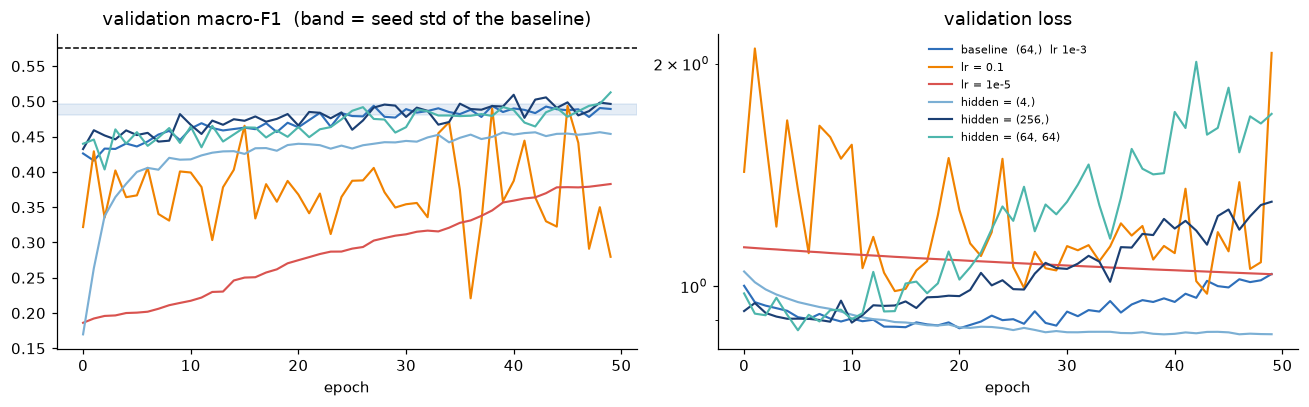

In [34]:
# How much does a run move with the random seed alone? (initial weights + mini-batch order), five seeds, validation only
seed_f1 = {}
for name in ["baseline  (64,)  lr 1e-3", "hidden = (256,)", "hidden = (64, 64)"]:
    _, arch, opt = runs[name]
    seed_f1[name] = np.array([fit(make_mlp(seed=s, **arch), **opt).val_f1.iloc[-1] for s in range(5)])
    print(f"{name:26s} seeds 0-4: {seed_f1[name].round(3)}   mean {seed_f1[name].mean():.3f}   std {seed_f1[name].std():.3f}")
seed_f1 = seed_f1["baseline  (64,)  lr 1e-3"]

f = curves["lr = 0.1"].val_f1
print(f"lr = 0.1, val macro-F1 over the 50 epochs: min {f.min():.3f}, median {f.median():.3f}, max {f.max():.3f}; "
      f"epochs below 0.35: {(f < 0.35).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cols = dict(zip(runs, ["#2E6FBA", "#F08200", "#D9534F", "#7BAFD4", "#1B3F73", "#4DB6AC"]))
for name, h in curves.items():
    axes[0].plot(h.index, h.val_f1, color=cols[name], label=name, lw=1.4)
    axes[1].plot(h.index, h.val_loss, color=cols[name], label=name, lw=1.4)
axes[0].axhline(FOREST, color="k", ls="--", lw=1, label=f"Session 5 forest ({FOREST:.3f})")
axes[0].axhspan(seed_f1.mean() - seed_f1.std(), seed_f1.mean() + seed_f1.std(), color="#2E6FBA", alpha=0.12)
axes[0].set_title("validation macro-F1  (band = seed std of the baseline)"); axes[0].set_xlabel("epoch")
axes[1].set_title("validation loss"); axes[1].set_xlabel("epoch"); axes[1].set_yscale("log"); axes[1].legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.show()

### Reading the mini-challenge

Final validation macro-F1, one change at a time (seed 0): baseline 0.489 · `lr=0.1` **0.280** · `lr=1e-5` **0.383** · `hidden=(4,)` 0.454 · `hidden=(256,)` 0.496 · `hidden=(64, 64)` 0.513. Number to beat: Session 5 forest, 0.575. **Nothing beats it** (best −0.062). Test split not touched.

- **`lr=0.1` is too large.** The steps overshoot, so the loss never settles (train loss 1.014, val loss 2.07, both near where training starts). F1 swings from epoch to epoch between 0.22 and 0.49 (median 0.37, final epoch 0.280), so its final number is a coin flip, not a result.
- **`lr=1e-5` is too small.** 50 epochs of 59 small steps barely move the weights: train loss 1.017, F1 0.383, and still rising at the last epoch (best epoch = 49). Nothing is broken; it would need roughly 100× more steps.
- **Width.** `(4,)` has 151 weights and cannot fit much: F1 0.454, but the lowest validation loss (0.861) because it cannot overfit either. `(256,)` has 9,475 weights, trains lower (0.545) but validates worse (1.30); its F1 is the baseline's within noise.
- **Depth.** `(64, 64)` gives 0.513, the best of the six, but it is one seed. Over seeds 0-4 the baseline is 0.488 ± 0.008, `(256,)` 0.498 ± 0.011 and `(64, 64)` 0.491 ± 0.011: **width above 64 and a second layer are indistinguishable from the baseline**; seed 0 was a lucky draw for the deep net. Only the learning rate (both directions) and the very narrow net move F1 by more than the seed noise.
- **Loss and F1 disagree.** For every network with room to learn, validation loss starts rising after roughly 15-25 epochs while F1 stays flat: F1 only looks at which class wins, the loss also punishes confidence. Early stopping on validation loss would be the cheap next step; more capacity is not.

**Choice:** keep `lr=1e-3`, one hidden layer of 64 (simplest net that reaches the plateau). On 33 summary statistics and 3,742 lesions the forest remains the stronger model, with the MLP about 0.08 behind on validation.

**Homework before Session 7** is answered in `06_homework.ipynb` (scoreboard, `nn.Conv2d` arguments, MLP on raw pixels).

### Homework · Before Session 7

1. Add your MLP's validation and test macro-F1 to the scoreboard, next to Session 5's forest.
2. Read the docs of nn.Conv2d: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than 33 features? Why?